# Creating DGPs with DowhyGCM

This notebook builds a DGP object **from scratch on top of the
dowhy-gcm library** (`pip install badgers[dowhy]`). badgers does
not replace dowhy — it wraps its machinery into the DGP protocol
so the object plugs into every causal generator. If the bundled
`DowhyGcmDGP` (linear regressor inside each `AdditiveNoiseModel`)
is not enough, subclass it: dowhy-gcm still does the estimation,
badgers still runs the graph.

For what an already-fitted DGP can do (sample, intervene,
generator wiring), read `Using-DGPs.ipynb` first.

## The protocol in one screen

A backend implements THREE per-node methods; `DGPMixin` provides
everything else (`fit` walks the graph in topological order,
`sample`/`intervene` run the cascades):

```python
fit_node(node, parents, data)      # estimate node's mechanism from data
response(node, parent_values)      # deterministic part f(parents)
draw_noise(node, rng, n)           # node's exogenous shock for n rows
```

Contract details:

* `fit_node` is called once per node; `data` is the full 2D array —
  resolve columns via `self.column_mapping`;
* NaN policy: estimate on complete-case rows only; raise
  `ValueError` when too few rows remain to identify the mechanism;
* `response` returns a 1D array (ravel sklearn outputs);
* `draw_noise` uses the caller's rng only — no global `np.random`;
* a fourth hook, `pick_parameters(rng)`, defaults to returning
  `self` — override it only for parameter-uncertainty backends
  (that is the PyMC notebook's topic).

## The problem: a non-linear mechanism

The bundled backends estimate **linear** effects with additive
noise. On data whose true mechanism is `Y = 2·sin(X) + noise` a
linear `f` averages over the wave. The fix is a small subclass
swapping the regressor inside the dowhy-gcm `AdditiveNoiseModel` —
everything else (fitting, sampling, do-machinery, generator
wiring) is inherited.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from numpy.random import default_rng

seed = 0
rng = default_rng(seed)

chain = nx.DiGraph([('X', 'Y'), ('Y', 'Z')])
column_mapping = {'X': 0, 'Y': 1, 'Z': 2}

n_samples = 200
Xnl = np.zeros((n_samples, 3))
Xnl[:, 0] = rng.normal(size=n_samples)
Xnl[:, 1] = 2.0 * np.sin(Xnl[:, 0]) + rng.normal(size=n_samples)
Xnl[:, 2] = 0.5 * Xnl[:, 1] * np.abs(Xnl[:, 1]) + rng.normal(size=n_samples)
print(Xnl.shape)

(200, 3)


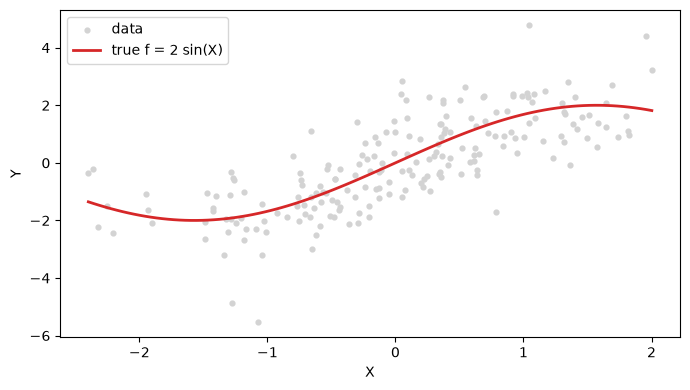

In [2]:
# viz: the non-linear ground truth
grid = np.linspace(Xnl[:, 0].min(), Xnl[:, 0].max(), 100)[:, None]
truth = 2.0 * np.sin(grid).ravel()

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(Xnl[:, 0], Xnl[:, 1], s=12, color='lightgray', label='data')
ax.plot(grid, truth, color='C3', lw=2, label='true f = 2 sin(X)')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.legend()
plt.tight_layout()

## The subclass: gradient boosting inside the ANM

`DowhyGcmDGP.fit_node` builds an `AdditiveNoiseModel` with a
linear `prediction_model`. Overriding `fit_node` to use dowhy's
hist-gradient-boosting regressor is the whole change; `response`
and `draw_noise` are inherited (they read the stored model and
residuals).

In [3]:
from badgers.core.dgp.backends.dowhy_gcm import DowhyGcmDGP
from dowhy.gcm import AdditiveNoiseModel
from dowhy.gcm.ml import create_hist_gradient_boost_regressor


class BoostedGcmDGP(DowhyGcmDGP):
    """DowhyGcmDGP with a non-linear f: hist gradient boosting
    instead of a linear regressor inside the AdditiveNoiseModel."""

    def fit_node(self, node, parents, data):
        if not parents:
            return super().fit_node(node, parents, data)
        col = self.column_mapping[node]
        mask = np.isfinite(data[:, col])
        for p in parents:
            mask &= np.isfinite(data[:, self.column_mapping[p]])
        d = data[mask]
        if d.shape[0] < len(parents) + 1:
            raise ValueError(f"Cannot fit node '{node}': too few complete rows")
        pcols = [self.column_mapping[p] for p in parents]
        anm = AdditiveNoiseModel(
            prediction_model=create_hist_gradient_boost_regressor())
        anm.fit(X=d[:, pcols], Y=d[:, col])
        self._anm[node] = anm
        self._residuals[node] = np.asarray(
            d[:, col] - anm.prediction_model.predict(d[:, pcols]).ravel(),
            dtype=float,
        )


boost_dgp = BoostedGcmDGP(chain, column_mapping).fit(Xnl)
print('fitted: BoostedGcmDGP')

C:\Users\siebert\PycharmProjects\badgers\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


fitted: BoostedGcmDGP


In [4]:
# verify: the non-linear backend reconstructs the true f
pred_boost = boost_dgp._anm['Y'].prediction_model.predict(grid).ravel()
rmse = float(np.sqrt(np.mean((pred_boost - truth) ** 2)))

# linear reference: the bundled DowhyGcmDGP
from badgers.core.dgp.backends.dowhy_gcm import DowhyGcmDGP
lin_dgp = DowhyGcmDGP(chain, column_mapping).fit(Xnl)
pred_lin = lin_dgp._anm['Y'].prediction_model.predict(grid).ravel()
rmse_lin = float(np.sqrt(np.mean((pred_lin - truth) ** 2)))

print(f'RMSE vs true f(X) = 2 sin(X): DowhyGcmDGP (linear) {rmse_lin:.3f} '
      f'-> BoostedGcmDGP {rmse:.3f}')

RMSE vs true f(X) = 2 sin(X): DowhyGcmDGP (linear) 0.505 -> BoostedGcmDGP 0.321


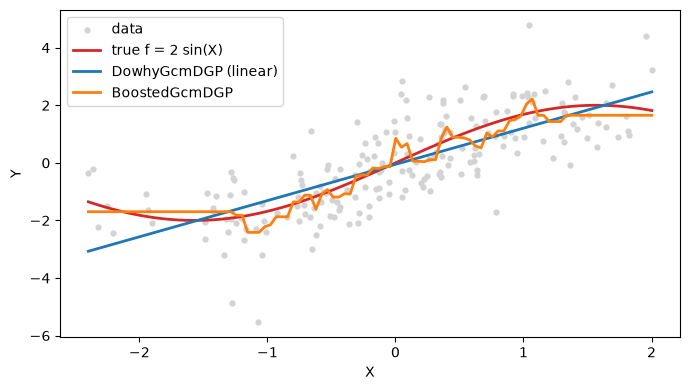

In [5]:
# viz: the two fits against the truth
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(Xnl[:, 0], Xnl[:, 1], s=12, color='lightgray', label='data')
ax.plot(grid, truth, color='C3', lw=2, label='true f = 2 sin(X)')
ax.plot(grid, pred_lin, color='C0', lw=2, label='DowhyGcmDGP (linear)')
ax.plot(grid, pred_boost, color='C1', lw=2, label='BoostedGcmDGP')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.legend()
plt.tight_layout()

## Conformance: the subclass through the generic machinery

A custom DGP is trustworthy when it passes the same checks as the
built-ins: finite samples with roughly matching marginals,
interventions that pin and recompute only descendants, and
reproducibility from the rng seed.

In [6]:
Xs = boost_dgp.sample(rng=np.random.default_rng(3), n=2000)
assert np.all(np.isfinite(Xs))
print('marginal means (train vs sampled):',
      np.round(Xnl.mean(axis=0), 2), np.round(Xs.mean(axis=0), 2))

Xi = boost_dgp.intervene(Xnl.copy(), ['Y'],
                         [np.full(n_samples, 10.0)],
                         rng=np.random.default_rng(4))
assert np.allclose(Xi[:, 1], 10.0)
assert np.allclose(Xi[:, 0], Xnl[:, 0])
print('Z after do(Y=10) ~', np.round(Xi[:, 2].mean(), 1),
      '(theory ~ 0.5*10*10 = 50)')

r1 = boost_dgp.sample(rng=np.random.default_rng(0), n=100)
r2 = boost_dgp.sample(rng=np.random.default_rng(0), n=100)
print('reproducible:', np.allclose(r1, r2))
assert np.allclose(r1, r2)

marginal means (train vs sampled): [ 0.02 -0.03 -0.04] [ 0.03 -0.01 -0.08]
Z after do(Y=10) ~ 4.0 (theory ~ 0.5*10*10 = 50)
reproducible: True


## Plugging the custom DGP into a generator

Because the subclass only touched `fit_node`, the whole do-machinery
and generator wiring work unchanged.

In [7]:
from badgers.generators.tabular_data.outliers.causal import CausalOutlierPropagationGenerator

gen = CausalOutlierPropagationGenerator(
    random_generator=np.random.default_rng(0), dgp=boost_dgp)
Xt, y_out = gen.generate(Xnl, y=None, perturbation_nodes=['X'],
                         n_outliers=5)
print('shape:', Xnl.shape, '->', Xt.shape)
print('original rows unchanged:', np.allclose(Xt[:n_samples], Xnl))

shape: (200, 3) -> (205, 3)
original rows unchanged: True


## Takeaways

- badgers wraps dowhy-gcm; it does not replace it. A custom DGP on
  dowhy-gcm = subclass `DowhyGcmDGP`, override what the linear
  default cannot express.
- Swapping the regressor inside the `AdditiveNoiseModel` is
  typically a `fit_node` override only — `response`/`draw_noise`
  are inherited.
- Verify against ground truth (RMSE) and run the conformance
  checks: marginals, do-pinning + ancestor preservation,
  reproducibility.